# Standardize Qwen open-vocab → extended YOLO `names` / `nc`

Use after **`qwen_sam3_image_pipeline.ipynb`** (open-vocab labels under `ARTIFACTS_ROOT`). Colab and a local machine can share the **same** `ARTIFACTS_ROOT` on Google Drive; only path prefixes differ (`/content/drive/...` vs `/Users/.../Google Drive/...`).

**This notebook (extend)** builds a **larger** class-name list from the union of Qwen-derived strings, then standardizes each string via **`ontology_canonical_renames.py`**: explicit **`CANONICAL_RENAMES`** plus **`canonicalize_label()`** tail heuristics (vehicles, signs, road furniture, etc.) to collapse long phrases. Segment rows are rewritten to the **index in the extended list**. For a **fixed small** taxonomy use **`remap_open_vocab_to_yolo.ipynb`** instead.

**Sister notebook:** **`remap_open_vocab_to_yolo.ipynb`** — maps open-vocab ids into a **small fixed** class list + alias table (typical closed-set training).

**Outputs:** writes **`extended_yolo_vocab.json`** under `ARTIFACTS_ROOT` (class order + rename table), backs up segment txts, then updates each run’s **`labels/segments/*.txt`**, **`classes.txt`**, and **`metadata.json`**. Runs already **`yolo_extended_from_open_vocab`** can be **re-synced** to the current global list when `REMAP_EXTENDED_TO_CURRENT_VOCAB` is True (fixes mixed `nc` across runs).

In [ ]:
from __future__ import annotations

import json
import shutil
import sys
from pathlib import Path

# Same layout as remap / mine_taxonomy (flat or nested image runs)
# ARTIFACTS_ROOT = Path("/Users/ral3ply/Documents/GitHub/visual-search/auto-labeler/outputs/uss_pf")

ARTIFACTS_ROOT = Path("/Users/ral3ply/Google Drive/My Drive/auto-labeler/all/outputs/uss_pf")

# Global registry from the image pipeline (same default as Step 3)
OPEN_VOCAB_STATE_JSON = ARTIFACTS_ROOT / "open_vocab_state.json"

# Optional: force these class names to appear first (indices 0..) if they exist after standardization.
CORE_CLASSES_FIRST: list[str] = [
    "person",
    "car",
    "van",
    "bus",
    "truck",
    "cone",
    "sign",
    "pole",
    "barrier",
    "vegetation",
    "road",
    "sidewalk",
]


def _autolabeler_package_dir() -> Path | None:
    """Find folder containing ontology_canonical_renames.py (cwd or parents / auto-labeler)."""
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "ontology_canonical_renames.py").is_file():
            return base
        if (base / "auto-labeler" / "ontology_canonical_renames.py").is_file():
            return base / "auto-labeler"
    return None


_pkg = _autolabeler_package_dir()
if _pkg is not None and str(_pkg) not in sys.path:
    sys.path.insert(0, str(_pkg))

try:
    from ontology_canonical_renames import CANONICAL_RENAMES as _CANONICAL_RENAMES
    from ontology_canonical_renames import canonicalize_label, norm_key

    CANONICAL_RENAMES = dict(_CANONICAL_RENAMES)
    print(
        f"Loaded CANONICAL_RENAMES: {len(CANONICAL_RENAMES)} rules + tail heuristics "
        "from ontology_canonical_renames.py"
    )
except Exception as _e:
    CANONICAL_RENAMES = {}

    def norm_key(s: str) -> str:
        return " ".join(str(s).strip().lower().split())

    def canonicalize_label(raw: str, renames: dict | None = None) -> str:
        table = CANONICAL_RENAMES if renames is None else renames
        k = norm_key(raw)
        if not k:
            return k
        return norm_key(table.get(k, k))

    print("WARN: could not import ontology_canonical_renames — using empty CANONICAL_RENAMES:", _e)

BACKUP_SEGMENT_TXT = True  # copy to labels/segments_open_vocab_orig/ before overwrite (open_vocab only)
# If some runs were extended with an older/smaller EXTENDED_NAMES, set True and re-run remap after rebuilding vocab.
REMAP_EXTENDED_TO_CURRENT_VOCAB = True
BACKUP_EXTENDED_BEFORE_RESYNC = True  # copy current segment txts to labels/segments_extended_prev/
DRY_RUN = False
WRITE_VOCAB_REPORT = True

In [ ]:
def standardize_label(raw: str) -> str:
    """Explicit merges + tail heuristics (see ontology_canonical_renames.canonicalize_label)."""
    return canonicalize_label(raw, CANONICAL_RENAMES)


def iter_image_run_dirs(artifacts_root: Path):
    if not artifacts_root.is_dir():
        raise FileNotFoundError(artifacts_root)
    for sub in sorted(artifacts_root.iterdir()):
        if not sub.is_dir() or sub.name.startswith("."):
            continue
        if (sub / "labels" / "metadata.json").is_file():
            yield sub.name, sub
            continue
        for nest in sorted(sub.iterdir()):
            if not nest.is_dir() or nest.name.startswith("."):
                continue
            if (nest / "labels" / "metadata.json").is_file():
                yield f"{sub.name}__{nest.name}", nest


def build_extended_class_order(
    state_path: Path,
    artifacts_root: Path,
    core_first: list[str],
) -> tuple[list[str], dict]:
    """
    Return (extended_yolo_class_names, report_dict).
    Order: CORE_CLASSES_FIRST (filtered), then first-seen from open_vocab_state id_to_prompt,
    then any extra strings from each run's metadata `yolo_class_names` (open_vocab **or** already-extended).
    """
    ordered: list[str] = []
    seen: set[str] = set()

    def add(canon: str) -> None:
        canon = norm_key(canon)
        if not canon or canon in seen:
            return
        seen.add(canon)
        ordered.append(canon)

    for c in core_first:
        add(standardize_label(c))

    if state_path.is_file():
        st = json.loads(state_path.read_text())
        for raw in st.get("id_to_prompt", []):
            add(standardize_label(str(raw)))

    for _key, run_dir in iter_image_run_dirs(artifacts_root):
        meta_path = run_dir / "labels" / "metadata.json"
        if not meta_path.is_file():
            continue
        try:
            meta = json.loads(meta_path.read_text())
        except Exception:
            continue
        m = meta.get("label_export_mode")
        if m not in ("open_vocab", "yolo_extended_from_open_vocab"):
            continue
        for raw in meta.get("yolo_class_names") or []:
            add(standardize_label(str(raw)))

    name_to_id = {n: i for i, n in enumerate(ordered)}
    report = {
        "artifacts_root": str(artifacts_root.resolve()),
        "open_vocab_state": str(state_path.resolve()) if state_path.is_file() else None,
        "nc": len(ordered),
        "yolo_class_names": ordered,
        "canonical_renames_used": dict(CANONICAL_RENAMES),
        "core_classes_first": list(core_first),
    }
    return ordered, report


def remap_segments_to_extended(
    seg_txt: Path,
    open_names: list[str],
    name_to_id: dict[str, int],
    *,
    skip_unmapped: bool = True,
) -> tuple[list[str], int, list[str]]:
    raw = seg_txt.read_text().strip()
    if not raw:
        return [], 0, []
    out_lines: list[str] = []
    dropped = 0
    issues: list[str] = []
    for li, line in enumerate(raw.splitlines(), 1):
        line = line.strip()
        if not line:
            continue
        parts = line.split()
        try:
            old_cid = int(float(parts[0]))
        except ValueError:
            issues.append(f"{seg_txt.name} L{li}: bad class id")
            continue
        if old_cid < 0 or old_cid >= len(open_names):
            issues.append(f"{seg_txt.name} L{li}: id {old_cid} out of range")
            continue
        canon = standardize_label(open_names[old_cid])
        if canon not in name_to_id:
            dropped += 1
            if not skip_unmapped:
                issues.append(f"{seg_txt.name} L{li}: no extended id for {canon!r}")
            continue
        nid = name_to_id[canon]
        out_lines.append(f"{nid} " + " ".join(parts[1:]))
    return out_lines, dropped, issues


print("Helpers OK")

In [10]:
EXTENDED_NAMES, vocab_report = build_extended_class_order(
    OPEN_VOCAB_STATE_JSON,
    ARTIFACTS_ROOT,
    CORE_CLASSES_FIRST,
)
name_to_id = {n: i for i, n in enumerate(EXTENDED_NAMES)}

print(f"Extended nc = {len(EXTENDED_NAMES)}")
print("First 40 names:", EXTENDED_NAMES[:40])

if WRITE_VOCAB_REPORT and not DRY_RUN:
    out_rep = ARTIFACTS_ROOT / "extended_yolo_vocab.json"
    out_rep.write_text(json.dumps(vocab_report, indent=2))
    print(f"Wrote {out_rep}")

Extended nc = 284
First 40 names: ['person', 'car', 'van', 'bus', 'truck', 'cone', 'sign', 'pole', 'barrier', 'vegetation', 'road', 'sidewalk', 'building', 'wall', 'overhead', 'parking lot', 'sky', 'planter', 'stairs', 'floor', 'fence', 'structure', 'ceiling', 'window blinds', 'trash bin', 'railing', 'road marking', 'bollard', 'carport', 'concrete pillars', 'box', 'cart', 'concrete overpass', 'concrete planter', 'gravel', 'scene artifact', 'carpet', 'airport terminal', 'concrete surface', 'vehicle part']
Wrote /Users/ral3ply/Google Drive/My Drive/auto-labeler/all/outputs/uss_pf/extended_yolo_vocab.json


### Full class list (audit ~nc classes)

The cell above prints **Extended nc** and only the **first 40** names. Run the next cell to write **all** classes to **`ARTIFACTS_ROOT/extended_yolo_class_list.txt`** (`id<TAB>name` per line). With hundreds of classes and ~2k images, many ids will be rare — tighten with **`CANONICAL_RENAMES`**, use **`remap_open_vocab_to_yolo.ipynb`** for a small fixed taxonomy, or **`mine_qwen_taxonomy.ipynb`** to see prompt frequencies.


In [11]:
_list_path = ARTIFACTS_ROOT / "extended_yolo_class_list.txt"
_text = "\n".join(f"{i:5d}\t{n}" for i, n in enumerate(EXTENDED_NAMES)) + "\n"
_list_path.write_text(_text, encoding="utf-8")
print("Wrote", _list_path.resolve(), "—", len(EXTENDED_NAMES), "classes")
_lines = _text.splitlines()
print("Head:")
for ln in _lines[:12]:
    print(" ", ln)
print("Tail:")
for ln in _lines[-8:]:
    print(" ", ln)


Wrote /Users/ral3ply/Library/CloudStorage/GoogleDrive-ali.rahim.taleqani@gmail.com/My Drive/auto-labeler/all/outputs/uss_pf/extended_yolo_class_list.txt — 284 classes
Head:
      0	person
      1	car
      2	van
      3	bus
      4	truck
      5	cone
      6	sign
      7	pole
      8	barrier
      9	vegetation
     10	road
     11	sidewalk
Tail:
    276	storage containers
    277	scaffolding
    278	snow on windshield
    279	fabric
    280	mesh
    281	indistinct background
    282	construction scaffolding
    283	concrete foundation


In [12]:
runs_ok = 0
runs_ok_open = 0
runs_ok_resync_ext = 0
runs_skip = 0
runs_err = 0
total_drop = 0
all_issues: list[str] = []

for key, run_dir in iter_image_run_dirs(ARTIFACTS_ROOT):
    meta_path = run_dir / "labels" / "metadata.json"
    seg_dir = run_dir / "labels" / "segments"
    try:
        meta = json.loads(meta_path.read_text())
    except Exception as e:
        runs_err += 1
        all_issues.append(f"{key}: metadata {e}")
        continue
    mode = meta.get("label_export_mode")
    if mode == "open_vocab":
        backup_dir = run_dir / "labels" / "segments_open_vocab_orig"
        do_backup = BACKUP_SEGMENT_TXT
    elif mode == "yolo_extended_from_open_vocab" and REMAP_EXTENDED_TO_CURRENT_VOCAB:
        backup_dir = run_dir / "labels" / "segments_extended_prev"
        do_backup = BACKUP_EXTENDED_BEFORE_RESYNC
    else:
        runs_skip += 1
        continue

    open_names = meta.get("yolo_class_names") or []
    if not isinstance(open_names, list) or not open_names:
        runs_err += 1
        all_issues.append(f"{key}: empty yolo_class_names")
        continue

    label_txts = [p for p in seg_dir.glob("*.txt") if p.name != "classes.txt"]
    if not label_txts:
        runs_err += 1
        all_issues.append(f"{key}: no segment txt")
        continue

    if do_backup and not DRY_RUN:
        backup_dir.mkdir(parents=True, exist_ok=True)
        for p in label_txts:
            shutil.copy2(p, backup_dir / p.name)

    run_drop = 0
    run_issues: list[str] = []
    for seg_txt in sorted(label_txts):
        new_lines, d, iss = remap_segments_to_extended(
            seg_txt, open_names, name_to_id, skip_unmapped=True
        )
        run_drop += d
        run_issues.extend(iss)
        if not DRY_RUN:
            seg_txt.write_text("\n".join(new_lines))

    if not DRY_RUN:
        (seg_dir / "classes.txt").write_text("\n".join(EXTENDED_NAMES))
        meta["label_export_mode"] = "yolo_extended_from_open_vocab"
        meta["yolo_nc"] = len(EXTENDED_NAMES)
        meta["yolo_class_names"] = list(EXTENDED_NAMES)
        meta["yolo_class_aliases"] = dict(CANONICAL_RENAMES)
        meta["standardize_open_vocab_note"] = (
            "Extended list built from open_vocab_state + open runs; "
            "CANONICAL_RENAMES applied before indexing."
        )
        if mode == "open_vocab":
            meta["open_vocab_class_names_snapshot"] = list(open_names)
        # extended resync: keep existing open_vocab_class_names_snapshot (true open-vocab list)
        meta_path.write_text(json.dumps(meta, indent=2))

    total_drop += run_drop
    all_issues.extend(run_issues)
    runs_ok += 1
    if mode == "open_vocab":
        runs_ok_open += 1
    else:
        runs_ok_resync_ext += 1
    print(f"{'[dry] ' if DRY_RUN else ''}{key}: rows_dropped_unmapped={run_drop} issues={len(run_issues)}")

print(
    f"\nRuns remapped={runs_ok} (open_vocab={runs_ok_open}, resync_extended={runs_ok_resync_ext}) "
    f"skipped={runs_skip} err={runs_err}"
)
print(f"Total dropped segment rows (canonical not in extended set)={total_drop}")
if all_issues:
    print("Sample issues:")
    for s in all_issues[:15]:
        print(" ", s)

106041__20190311_LB_XO2617_012_165618_Front.avi: rows_dropped_unmapped=0 issues=0
106041__20190311_LB_XO2617_012_165618_Rear.avi: rows_dropped_unmapped=0 issues=0
106042__20190411_LB_XO2617_171125_Front.avi: rows_dropped_unmapped=0 issues=0
106042__20190411_LB_XO2617_171125_Rear.avi: rows_dropped_unmapped=0 issues=0
106060__20190307_LB_XO2617_003_125706_Front.avi: rows_dropped_unmapped=0 issues=0
106060__20190307_LB_XO2617_003_125706_Rear.avi: rows_dropped_unmapped=0 issues=0
106064__20190329_LB_XO2617_092212_Front.avi: rows_dropped_unmapped=0 issues=0
106064__20190329_LB_XO2617_092212_Rear.avi: rows_dropped_unmapped=0 issues=0
106294__20190411_LB_XO2617_110929_Front.avi: rows_dropped_unmapped=0 issues=0
106294__20190411_LB_XO2617_110929_Rear.avi: rows_dropped_unmapped=0 issues=0
106295__20190411_LB_XO2617_165352_Front.avi: rows_dropped_unmapped=0 issues=0
106295__20190411_LB_XO2617_165352_Rear.avi: rows_dropped_unmapped=0 issues=0
106296__20190411_LB_XO2617_111529_Front.avi: rows_drop

### Class distribution after standardization

Run **after** the remap cell. Scans `labels/segments/*.txt` for runs with `label_export_mode=yolo_extended_from_open_vocab`, counts each segment row by class id, prints the **top 50**, writes **`ARTIFACTS_ROOT/extended_yolo_class_counts.csv`**, and plots the **top 35** if matplotlib is available.


Class distribution after standardization: 22,501 segment rows from 1972 runs / 1972 segment files; 202 classes with ≥1 instance (extended nc=284).
 rank       count      pct  class
------------------------------------------------------------------------
    1       5,201   23.11%  vegetation
    2       4,242   18.85%  building
    3       3,684   16.37%  car
    4       1,013    4.50%  road
    5         818    3.64%  sign
    6         755    3.36%  wall
    7         728    3.24%  fence
    8         531    2.36%  pole
    9         424    1.88%  road marking
   10         420    1.87%  barrier
   11         369    1.64%  parking lot
   12         345    1.53%  railing
   13         340    1.51%  structure
   14         325    1.44%  pillars
   15         238    1.06%  sidewalk
   16         183    0.81%  sky
   17         174    0.77%  snow
   18         173    0.77%  floor
   19         172    0.76%  ceiling
   20         125    0.56%  flowers
   21         113    0.50%  planter
 

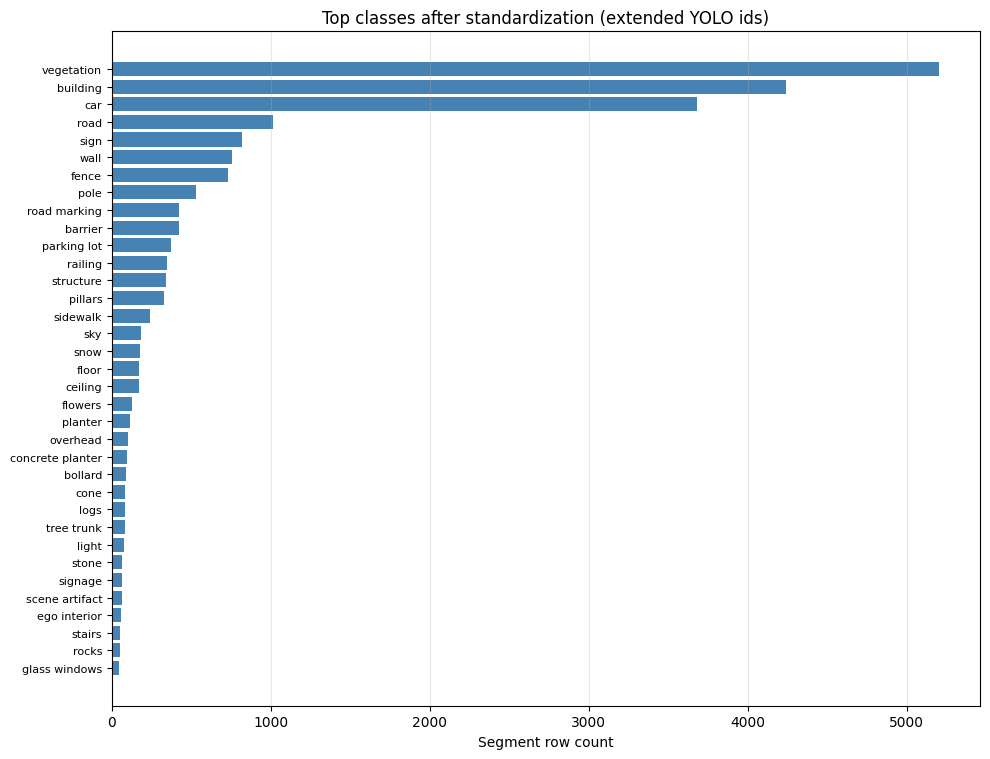

In [13]:
import csv
from collections import Counter


def collect_extended_class_counts(artifacts_root: Path) -> tuple[Counter[str], int, int]:
    """Count segment rows per canonical class name after standardize (extended ids)."""
    counts: Counter[str] = Counter()
    runs_used = 0
    files_used = 0
    for _key, run_dir in iter_image_run_dirs(artifacts_root):
        meta_path = run_dir / "labels" / "metadata.json"
        if not meta_path.is_file():
            continue
        try:
            meta = json.loads(meta_path.read_text())
        except Exception:
            continue
        if meta.get("label_export_mode") != "yolo_extended_from_open_vocab":
            continue
        names = list(meta.get("yolo_class_names") or [])
        if not names:
            names = list(EXTENDED_NAMES)
        seg_dir = run_dir / "labels" / "segments"
        if not seg_dir.is_dir():
            continue
        run_hits = False
        for seg_txt in sorted(seg_dir.glob("*.txt")):
            if seg_txt.name == "classes.txt":
                continue
            try:
                raw = seg_txt.read_text(encoding="utf-8", errors="replace")
            except Exception:
                continue
            for line in raw.splitlines():
                line = line.strip()
                if not line:
                    continue
                parts = line.split()
                try:
                    cid = int(float(parts[0]))
                except ValueError:
                    continue
                if cid < 0 or cid >= len(names):
                    continue
                counts[names[cid]] += 1
                run_hits = True
            if raw.strip():
                files_used += 1
        if run_hits:
            runs_used += 1
    return counts, runs_used, files_used


class_counts, runs_hist, files_hist = collect_extended_class_counts(ARTIFACTS_ROOT)
total_rows = int(sum(class_counts.values()))

if total_rows == 0:
    print(
        "No segment rows found for label_export_mode=yolo_extended_from_open_vocab. "
        "Run the remap cell above first (and ensure DRY_RUN is False)."
    )
else:
    ranked = class_counts.most_common()
    n_present = len(ranked)
    print(
        f"Class distribution after standardization: {total_rows:,} segment rows "
        f"from {runs_hist} runs / {files_hist} segment files; "
        f"{n_present} classes with ≥1 instance (extended nc={len(EXTENDED_NAMES)})."
    )
    print(f"{'rank':>5}  {'count':>10}  {'pct':>7}  class")
    print("-" * 72)
    for i, (name, c) in enumerate(ranked, 1):
        pct = 100.0 * c / total_rows
        print(f"{i:5d}  {c:10,}  {pct:6.2f}%  {name}")
        if i >= 50:
            tail = len(ranked) - 50
            if tail > 0:
                print(f"  … {tail} more classes (see CSV)")
            break

    _csv = ARTIFACTS_ROOT / "extended_yolo_class_counts.csv"
    with _csv.open("w", newline="", encoding="utf-8") as fp:
        w = csv.writer(fp)
        w.writerow(["class_name", "count", "pct_of_all_segments"])
        for name, c in ranked:
            w.writerow([name, c, round(100.0 * c / total_rows, 6)])
    print(f"\nWrote full table: {_csv.resolve()}")

    try:
        import matplotlib.pyplot as plt

        top_k = min(35, len(ranked))
        if top_k:
            labels = [n[:42] + ("…" if len(n) > 42 else "") for n, _ in ranked[:top_k]]
            vals = [c for _, c in ranked[:top_k]]
            fig, ax = plt.subplots(figsize=(10, max(4, top_k * 0.22)))
            ax.barh(range(top_k), vals, color="steelblue")
            ax.set_yticks(range(top_k))
            ax.set_yticklabels(labels, fontsize=8)
            ax.invert_yaxis()
            ax.set_xlabel("Segment row count")
            ax.set_title("Top classes after standardization (extended YOLO ids)")
            ax.grid(axis="x", alpha=0.3)
            plt.tight_layout()
            plt.show()
    except Exception as _plot_e:
        print("(matplotlib not available or plot failed —", _plot_e, ")")

### Ready for training?

Run the cell below **after** remap + distribution. It checks that (1) every extended run shares the **same** `yolo_class_names` as `EXTENDED_NAMES`, (2) segment class ids are in range, (3) `extended_yolo_vocab.json` matches this session. If you see **multiple `nc` variants**, re-run the **vocab** cell (so `EXTENDED_NAMES` unions **all** runs’ class lists), then the **remap** cell with `REMAP_EXTENDED_TO_CURRENT_VOCAB=True` (default). Then in **`train_yolo_seg_from_image_pipeline.ipynb`**: same `ARTIFACTS_ROOT`, **`CLASS_NAMES_UNIFY_MODE = 'strict'`** (or `'majority'`), **re-materialize** `DATASET_ROOT`, and confirm **Label sanity** shows **0 bad file(s)**.


In [14]:
def verify_artifacts_ready_for_training(artifacts_root: Path, expected_names: list[str]) -> bool:
    """Gates before train_yolo_seg_from_image_pipeline: one shared vocab + valid ids."""
    from collections import Counter, defaultdict

    exp = tuple(expected_names)
    mode_ct = Counter()
    variants: dict[tuple[str, ...], list[str]] = defaultdict(list)
    oob: list[str] = []

    for key, run_dir in iter_image_run_dirs(artifacts_root):
        meta_path = run_dir / "labels" / "metadata.json"
        if not meta_path.is_file():
            continue
        try:
            meta = json.loads(meta_path.read_text())
        except Exception:
            continue
        mode = str(meta.get("label_export_mode") or "missing")
        mode_ct[mode] += 1
        if mode != "yolo_extended_from_open_vocab":
            continue
        names = list(meta.get("yolo_class_names") or [])
        variants[tuple(names)].append(key)
        lim = len(names)
        if lim == 0:
            continue
        seg_dir = run_dir / "labels" / "segments"
        if not seg_dir.is_dir():
            continue
        for seg_txt in seg_dir.glob("*.txt"):
            if seg_txt.name == "classes.txt":
                continue
            try:
                raw = seg_txt.read_text(encoding="utf-8", errors="replace")
            except Exception:
                continue
            for line in raw.splitlines():
                parts = line.split()
                if not parts:
                    continue
                try:
                    cid = int(float(parts[0]))
                except ValueError:
                    continue
                if cid < 0 or cid >= lim:
                    oob.append(f"{key} {seg_txt.name}: class_id={cid} nc={lim}")
                    if len(oob) >= 25:
                        break
            if len(oob) >= 25:
                break
        if len(oob) >= 25:
            break

    print("Runs with metadata.json by label_export_mode:")
    for m, c in sorted(mode_ct.items(), key=lambda x: -x[1]):
        print(f"  {c:6d}  {m}")

    ok = True
    n_ext = mode_ct.get("yolo_extended_from_open_vocab", 0)
    if n_ext == 0:
        print("\nFAIL: no standardized runs — run remap with DRY_RUN=False.")
        return False

    if len(variants) != 1:
        print(f"\nFAIL: {len(variants)} different yolo_class_names among extended runs (need exactly 1).")
        for i, (vt, keys) in enumerate(sorted(variants.items(), key=lambda x: -len(x[1]))[:4]):
            print(f"  variant {i+1}: nc={len(vt)} runs={len(keys)} e.g. {keys[0]!r}")
        ok = False
    else:
        only = next(iter(variants.keys()))
        if only != exp:
            print(
                "\nFAIL: on-disk class list != this notebook's EXTENDED_NAMES. "
                "Re-run the vocab cell (build EXTENDED_NAMES) then remap in one session."
            )
            print(f"  disk nc={len(only)}  notebook nc={len(exp)}")
            for j in range(min(8, len(only), len(exp))):
                if j < len(only) and j < len(exp) and only[j] != exp[j]:
                    print(f"  first diff at index {j}: disk={only[j]!r} nb={exp[j]!r}")
                    break
            ok = False
        else:
            print(f"\nPASS: all {n_ext} extended runs share identical yolo_class_names (nc={len(exp)}).")

    if oob:
        print(f"\nFAIL: {len(oob)} out-of-range class id(s) (showing up to 25):")
        for s in oob[:25]:
            print(" ", s)
        ok = False
    else:
        print("PASS: no out-of-range class ids in scanned segment files.")

    vp = artifacts_root / "extended_yolo_vocab.json"
    if vp.is_file():
        doc = json.loads(vp.read_text())
        saved = tuple(doc.get("yolo_class_names") or [])
        if saved != exp:
            print("\nWARN: extended_yolo_vocab.json yolo_class_names != EXTENDED_NAMES (re-run vocab write cell).")
            ok = False
        else:
            print("PASS: extended_yolo_vocab.json matches EXTENDED_NAMES.")
    else:
        print("\nWARN: extended_yolo_vocab.json missing — run vocab report cell.")

    return ok


_train_ready = verify_artifacts_ready_for_training(ARTIFACTS_ROOT, EXTENDED_NAMES)
print("\n===", "OK to materialize dataset + train" if _train_ready else "NOT OK — fix issues above", "===")


Runs with metadata.json by label_export_mode:
    1979  yolo_extended_from_open_vocab

PASS: all 1979 extended runs share identical yolo_class_names (nc=284).
PASS: no out-of-range class ids in scanned segment files.
PASS: extended_yolo_vocab.json matches EXTENDED_NAMES.

=== OK to materialize dataset + train ===
